# Hospital Operations Analytics - Exploratory Analysis
Excel-style inspection, profiling and preliminary analysis of the **cleaned** synthetic dataset (`data/processed`), done *before* the SQL/Power BI work to understand shape, quality and the first signals. All numbers are computed live from the CSVs.

> **Data note:** the dataset is synthetic (seed 42). Operational patterns and scenarios were injected deliberately by `scripts/generate_dataset.py`; findings demonstrate the analytical method, not real hospital performance.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
pd.options.display.float_format = '{:,.2f}'.format
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 100, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left'})
BLUE, TEAL, GREY, AMBER = '#1F5FA8', '#1A9E9A', '#B8C2CC', '#E6A117'
P = Path('..') / 'data' / 'processed'
T = {n: pd.read_csv(P / f'{n}.csv') for n in ['patients','admissions','departments','doctors','beds','emergency_visits','doctor_activity','readmissions']}
pd.DataFrame({'rows': {k: len(v) for k, v in T.items()}, 'columns': {k: v.shape[1] for k, v in T.items()}})

,rows,columns
patients,27007,6
admissions,16314,11
departments,11,4
doctors,58,6
beds,106,4
emergency_visits,35713,9
doctor_activity,44214,6
readmissions,1866,5


## 1. Profiling: nulls and domains
Nulls are expected only where the business logic says so (cancelled admissions have no bed/discharge; open stays have no discharge; LWBS visits have no consultation; ED-to-admission link is optional).

In [2]:
nulls = pd.concat({k: v.isna().sum()[v.isna().sum() > 0] for k, v in T.items()})
nulls.to_frame('null_count')

null_count
admissions       discharge_date                471
                 bed_id                        396
                 discharge_type                471
emergency_visits consultation_datetime         792
                 admission_id                25888

In [3]:
a = T['admissions']
print(a.admission_status.value_counts().to_string()); print()
print(pd.crosstab(a.admission_status, a.discharge_type.fillna('(none)')))

admission_status
Discharged    15843
Cancelled       396
Admitted         75

discharge_type    (none)  Deceased  Discharged Home  \
admission_status                                      
Admitted              75         0                0   
Cancelled            396         0                0   
Discharged             0       376            13643   

discharge_type    Discharged Home with Follow-up  Left Against Medical Advice  \
admission_status                                                                
Admitted                                       0                            0   
Cancelled                                      0                            0   
Discharged                                  1093                          322   

discharge_type    Transferred to Another Facility  
admission_status                                   
Admitted                                        0  
Cancelled                                       0  
Discharged                      

## 2. Referential and logical sanity (spot checks - the full 72-test suite is `scripts/validate_data.py`)

In [4]:
a['admission_date'] = pd.to_datetime(a.admission_date); a['discharge_date'] = pd.to_datetime(a.discharge_date)
bd = a[a.bed_id.notna()].merge(T['beds'], on='bed_id', suffixes=('', '_b'))
dd = a.merge(T['doctors'], on='doctor_id', suffixes=('', '_d'))
chk = {
 'admissions with unknown patient': (~a.patient_id.isin(T['patients'].patient_id)).sum(),
 'discharge before admission': (a.discharge_date < a.admission_date).sum(),
 'bed dept != admission dept': (bd.department_id != bd.department_id_b).sum(),
 'doctor dept != admission dept': (dd.department_id != dd.department_id_d).sum(),
 'readmissions with unknown admission': (~T['readmissions'].readmission_admission_id.isin(a.admission_id)).sum(),
}
pd.Series(chk, name='violations')

admissions with unknown patient        0
discharge before admission             0
bed dept != admission dept             0
doctor dept != admission dept          0
readmissions with unknown admission    0
Name: violations, dtype: int64

## 3. Admissions: volume, type, seasonality (reporting window 2023-2025)

C:\Users\shaur\AppData\Local\Temp\ipykernel_2780\4114784529.py:5: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  t = w.groupby([w.admission_date.dt.dayofweek, 'admission_type']).size().unstack().reindex(range(7)); t.index = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']


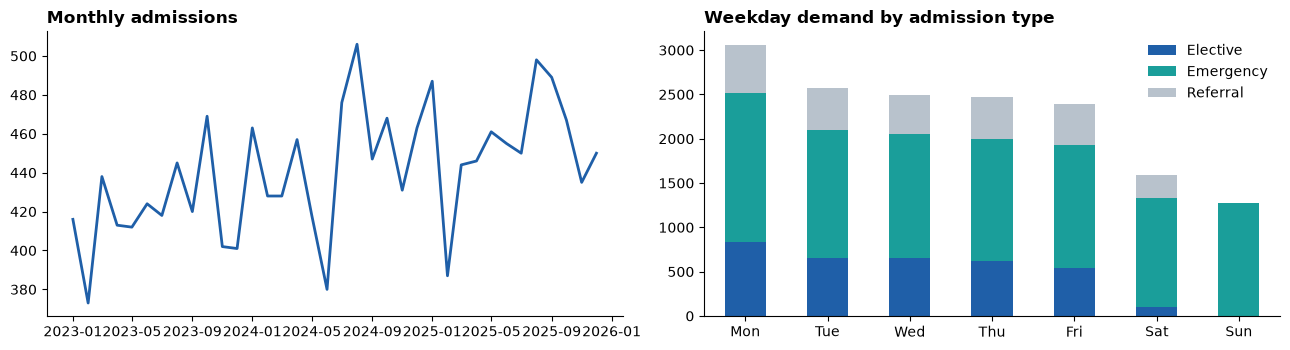

{'Emergency': 0.617, 'Elective': 0.215, 'Referral': 0.168}


In [5]:
w = a[(a.admission_status != 'Cancelled') & (a.admission_date >= '2023-01-01')]
m = w.groupby(w.admission_date.dt.to_period('M')).size()
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].plot(m.index.to_timestamp(), m.values, color=BLUE, lw=2); ax[0].set_title('Monthly admissions')
t = w.groupby([w.admission_date.dt.dayofweek, 'admission_type']).size().unstack().reindex(range(7)); t.index = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']
t.plot.bar(stacked=True, ax=ax[1], color=[BLUE, TEAL, GREY]); ax[1].set_title('Weekday demand by admission type'); ax[1].legend(frameon=False); plt.xticks(rotation=0); plt.tight_layout(); plt.show()
print(w.admission_type.value_counts(normalize=True).round(3).to_dict())

## 4. Length of stay (completed stays only)

In [6]:
d = a[a.admission_status == 'Discharged'].copy(); d['los'] = (d.discharge_date - d.admission_date).dt.days
d = d.merge(T['departments'][['department_id','department_name']], on='department_id')
s = d.groupby('department_name').los.agg(['count','mean','median', lambda x: x.quantile(.9), 'max']); s.columns = ['stays','ALOS','median','P90','max']
s.sort_values('ALOS', ascending=False)

,stays,ALOS,median,P90,max
department_name,,,,,
Neurology,816,6.93,6.00,12.00,39
Critical Care (ICU),1054,6.93,5.00,15.00,60
Pulmonology,984,6.40,6.00,11.00,26
Orthopedics,1252,6.29,6.00,10.00,41
General Medicine,2574,5.86,5.00,10.00,57
Oncology,820,5.57,5.00,10.00,23
Cardiology,2271,4.85,4.00,8.00,29
General Surgery,2383,3.89,3.00,7.00,20
Obstetrics & Gynecology,1861,3.32,3.00,5.00,8


## 5. Bed occupancy - interval based (never admissions / beds)
Occupied on day D when `admission_date <= D < discharge_date` (open stays run to the snapshot date). Staffed beds exclude `Closed` beds.

In [7]:
days = pd.date_range('2023-01-01', '2025-12-31'); snap = pd.Timestamp('2026-01-01')
nc = a[a.admission_status != 'Cancelled'].copy(); nc['end'] = nc.discharge_date.fillna(snap)
staffed = T['beds'][T['beds'].bed_status != 'Closed'].groupby('department_id').size()
d64 = days.values.astype('datetime64[D]'); rows = []
for dep, g in nc.groupby('department_id'):
    ad, en = g.admission_date.values.astype('datetime64[D]'), g.end.values.astype('datetime64[D]')
    rows.append(pd.Series(((ad[None, :] <= d64[:, None]) & (en[None, :] > d64[:, None])).sum(1), index=days, name=dep))
occ = pd.concat(rows, axis=1)
bor = (occ.sum() / (staffed * len(days))).rename('BOR').to_frame().join(T['departments'].set_index('department_id').department_name)
bor['share_of_days_>=85%'] = ((occ / staffed) >= .85).mean().round(3)
print('Hospital BOR =', round(occ.values.sum() / (staffed.sum() * len(days)), 4))
bor.sort_values('BOR', ascending=False)

Hospital BOR = 0.7069


,BOR,department_name,share_of_days_>=85%
D02,0.86,General Medicine,0.64
D03,0.84,Cardiology,0.56
D11,0.83,Critical Care (ICU),0.63
D10,0.82,Pulmonology,0.67
D08,0.74,Neurology,0.47
D04,0.65,Orthopedics,0.20
D05,0.61,General Surgery,0.17
D09,0.60,Oncology,0.26
D07,0.56,Obstetrics & Gynecology,0.12
D06,0.52,Pediatrics,0.11


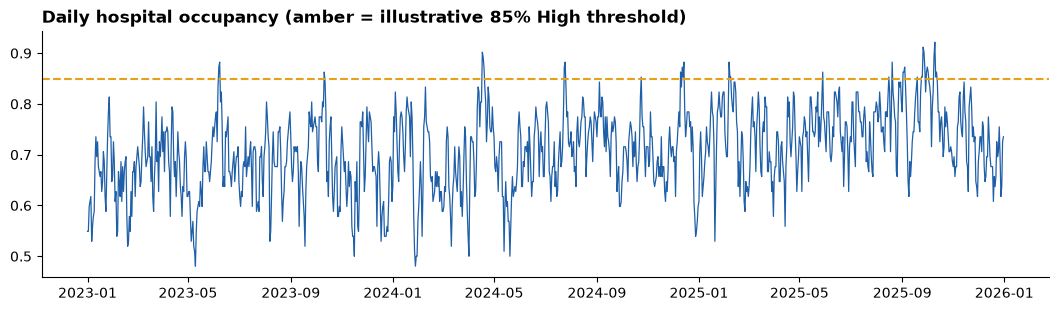

Weekday occupancy (0=Mon): {0: 0.663, 1: 0.696, 2: 0.721, 3: 0.735, 4: 0.73, 5: 0.709, 6: 0.694}


C:\Users\shaur\AppData\Local\Temp\ipykernel_2780\3514953613.py:4: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  print('Weekday occupancy (0=Mon):', hosp.groupby(hosp.index.dayofweek).mean().round(3).to_dict())


In [8]:
hosp = occ.sum(axis=1) / staffed.sum()
fig, ax = plt.subplots(figsize=(13, 3.2)); ax.plot(hosp.index, hosp.values, color=BLUE, lw=.9); ax.axhline(.85, color=AMBER, ls='--')
ax.set_title('Daily hospital occupancy (amber = illustrative 85% High threshold)'); plt.show()
print('Weekday occupancy (0=Mon):', hosp.groupby(hosp.index.dayofweek).mean().round(3).to_dict())

## 6. Emergency department

visits=35,679  mean wait=50.8  median=41.2  turnaround=308  LWBS=2.2%

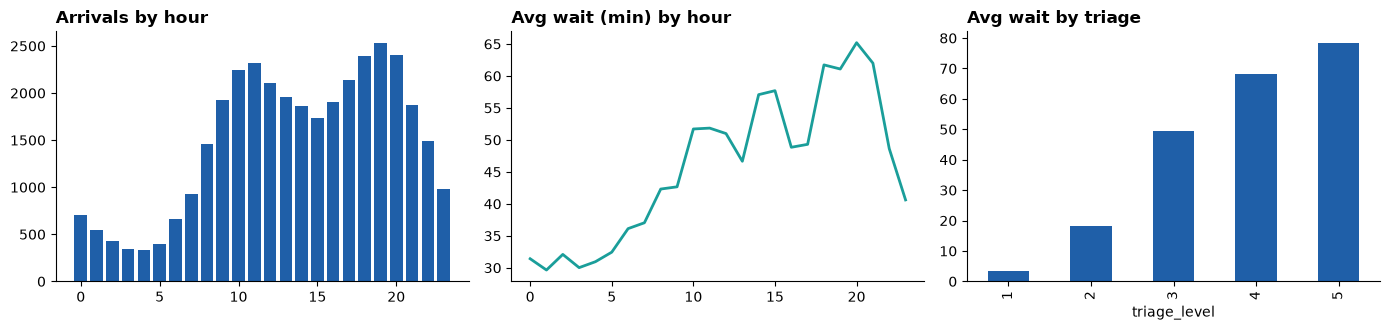

,count,mean,median
disposition_type,,,
Discharged Home,18905,170.61,155.02
Admitted,9791,666.05,335.18
Referred for Outpatient Follow-up,3927,167.12,152.50
Transferred,1187,272.95,246.67
Left Against Medical Advice,990,180.92,166.82
Left Without Being Seen,792,91.73,77.32
Deceased,87,199.64,179.95


In [9]:
e = T['emergency_visits']
for c in ['arrival_datetime', 'consultation_datetime', 'disposition_datetime']: e[c] = pd.to_datetime(e[c])
e = e[e.arrival_datetime >= '2023-01-01'].copy()
e['wait'] = (e.consultation_datetime - e.arrival_datetime).dt.total_seconds() / 60; e['tat'] = (e.disposition_datetime - e.arrival_datetime).dt.total_seconds() / 60
print(f"visits={len(e):,}  mean wait={e.wait.mean():.1f}  median={e.wait.median():.1f}  turnaround={e.tat.mean():.0f}  LWBS={(e.disposition_type == 'Left Without Being Seen').mean():.1%}")
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
h = e.groupby(e.arrival_datetime.dt.hour).agg(v=('wait', 'size'), w=('wait', 'mean'))
ax[0].bar(h.index, h.v, color=BLUE); ax[0].set_title('Arrivals by hour')
ax[1].plot(h.index, h.w, color=TEAL, lw=2); ax[1].set_title('Avg wait (min) by hour')
e.groupby('triage_level').wait.mean().plot.bar(ax=ax[2], color=BLUE); ax[2].set_title('Avg wait by triage'); plt.tight_layout(); plt.show()
e.groupby('disposition_type').tat.agg(['count', 'mean', 'median']).sort_values('count', ascending=False)

## 7. Readmissions (30-day, eligible discharges only)

In [10]:
r = T['readmissions']
elig = d[~d.discharge_type.isin(['Deceased', 'Transferred to Another Facility']) & (d.discharge_date >= '2023-01-01') & (d.discharge_date + pd.Timedelta(days=30) <= '2025-12-31')].copy()
back = set(r[r.days_between_admissions <= 30].original_admission_id); elig['r30'] = elig.admission_id.isin(back)
print(f"eligible discharges={len(elig):,}  30-day readmissions={elig.r30.sum():,}  rate={elig.r30.mean():.2%}")
elig.groupby('department_name').r30.agg(['size', 'sum', 'mean']).rename(columns={'size': 'eligible', 'sum': 'readmitted', 'mean': 'rate'}).sort_values('rate', ascending=False)

eligible discharges=14,655  30-day readmissions=1,264  rate=8.63%


,eligible,readmitted,rate
department_name,,,
Cardiology,2088,347,0.17
Pulmonology,895,139,0.16
Oncology,709,103,0.15
General Medicine,2420,248,0.10
Neurology,725,74,0.10
Critical Care (ICU),823,46,0.06
Pediatrics,1732,93,0.05
General Surgery,2254,108,0.05
Orthopedics,1204,45,0.04


## 8. Doctor utilisation

In [11]:
da = T['doctor_activity'].merge(T['doctors'], on='doctor_id').merge(T['departments'][['department_id', 'department_name']], on='department_id')
da = da[da.activity_date >= '2023-01-01']
u = da.groupby('department_name')[['patient_consultation_hours', 'scheduled_hours']].sum(); u['utilisation'] = u.iloc[:, 0] / u.iloc[:, 1]
print('Hospital utilisation =', round(u.iloc[:, 0].sum() / u.iloc[:, 1].sum(), 4)); u.sort_values('utilisation', ascending=False)

Hospital utilisation = 0.7947


,patient_consultation_hours,scheduled_hours,utilisation
department_name,,,
Pulmonology,"18,577.53","21,512.00",0.86
General Surgery,"26,693.64","31,717.00",0.84
Critical Care (ICU),"24,504.45","29,590.50",0.83
Cardiology,"27,302.83","32,979.00",0.83
Emergency Medicine,"45,822.83","55,445.00",0.83
Orthopedics,"24,925.64","30,922.00",0.81
General Medicine,"35,321.42","45,232.00",0.78
Pediatrics,"22,451.96","29,664.50",0.76
Obstetrics & Gynecology,"18,483.53","24,707.50",0.75


## 9. What this tells us / next steps
* Bed pressure is concentrated in a handful of departments (section 5) while others run well below capacity - a *distribution* problem rather than a hospital-wide shortage.
* ED waits are shaped by hour of day and triage level; turnaround of **admitted** patients is dominated by waiting for a ward bed.
* Readmission rates vary strongly by department and must always be read with their denominators (section 7).
* The formal, reconciled KPIs and the 41 SQL analyses are in `database/` and `analysis/sql_results/`; insights are in `documentation/Business_Insights_Report.md`.